

TRANSPORTATION PROBLEM - THREE SCENARIOS

Total Supply = 200


SCENARIO 1 - DEMAND GREATER THAN SUPPLY

===== Balance Check =====
Total Supply  = 200
Total Demand  = 220

The Transportation Problem is NOT BALANCED.
Demand is greater than Supply by 20
Adding a DUMMY SOURCE with supply 20

===== Vogel's Approximation Method (VAM) =====
Company 1 -> Bank = 20 units
Company 1 -> Airline = 20 units
Company 2 -> Hospital = 20 units
Company 2 -> Insurance = 20 units
Company 2 -> Media = 20 units
Company 3 -> Store = 20 units
Company 3 -> University = 10 units
Company 3 -> Ministry = 20 units
Company 4 -> Bank = 10 units
Company 4 -> Hospital = 10 units
Company 4 -> University = 10 units
Company 4 -> Factory = 20 units
Dummy Source -> Telecom = 20 units
Total cost by VAM = 1310.0 EGP

===== Least Cost Method =====
Company 1 -> Bank = 10 units
Company 1 -> Insurance = 20 units
Company 1 -> Airline = 10 units
Company 2 -> Hospital = 30 units
Company 2 -> Airline = 10 units
Company 2 -> Media =

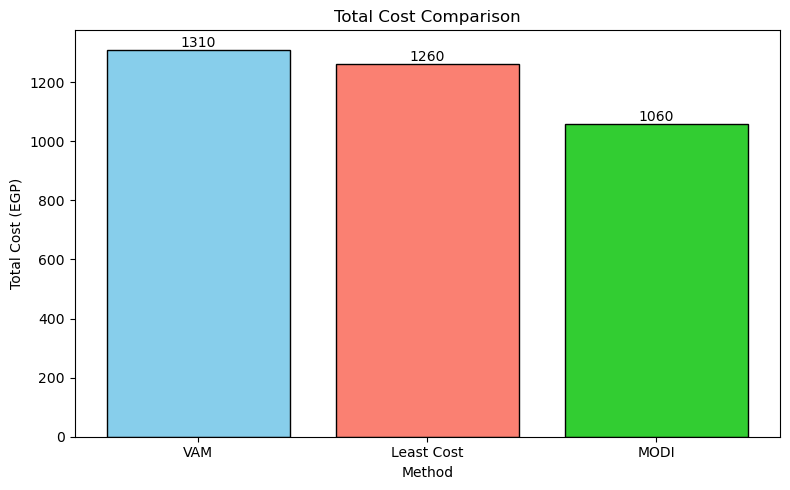

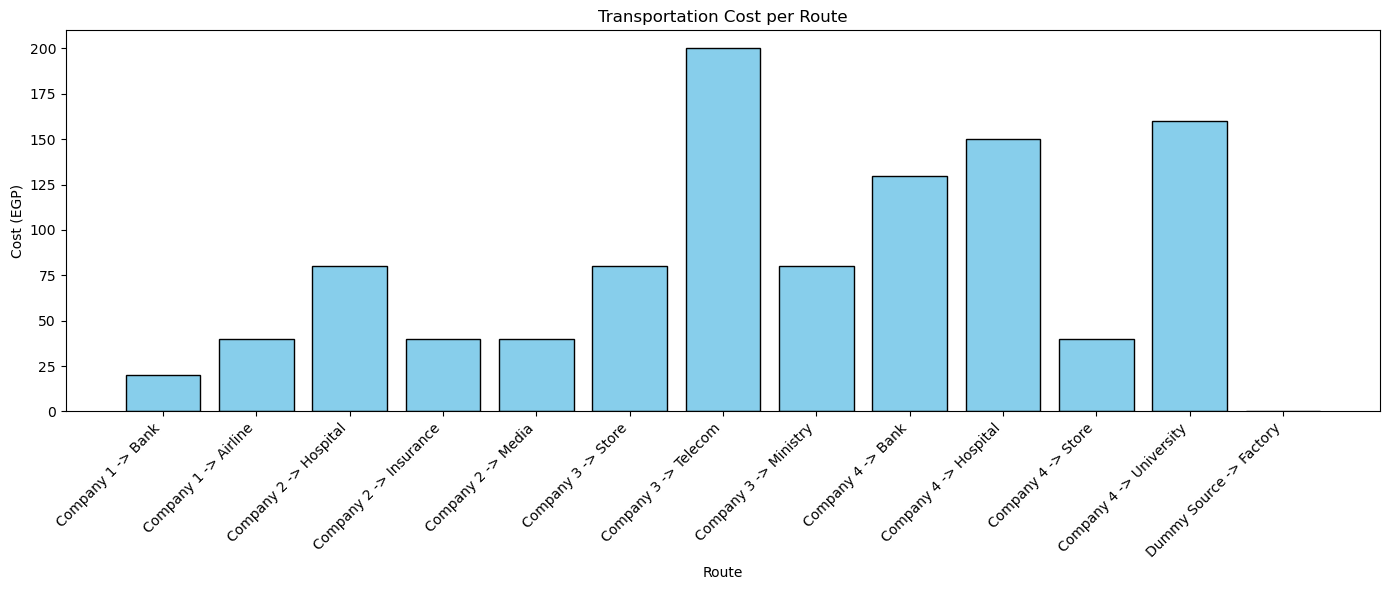

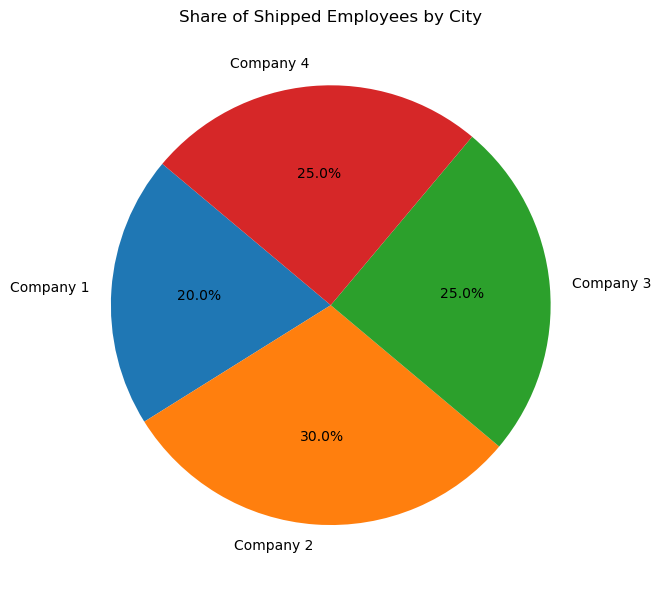


Generating graphs for: SCENARIO 2 - SUPPLY GREATER THAN DEMAND


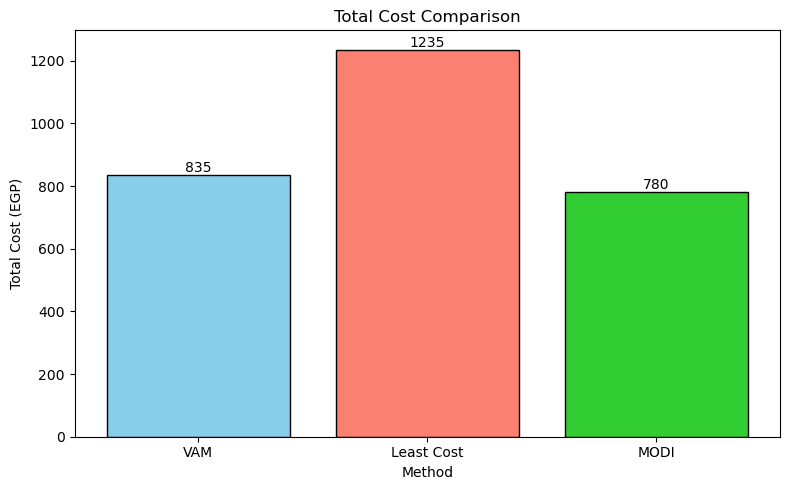

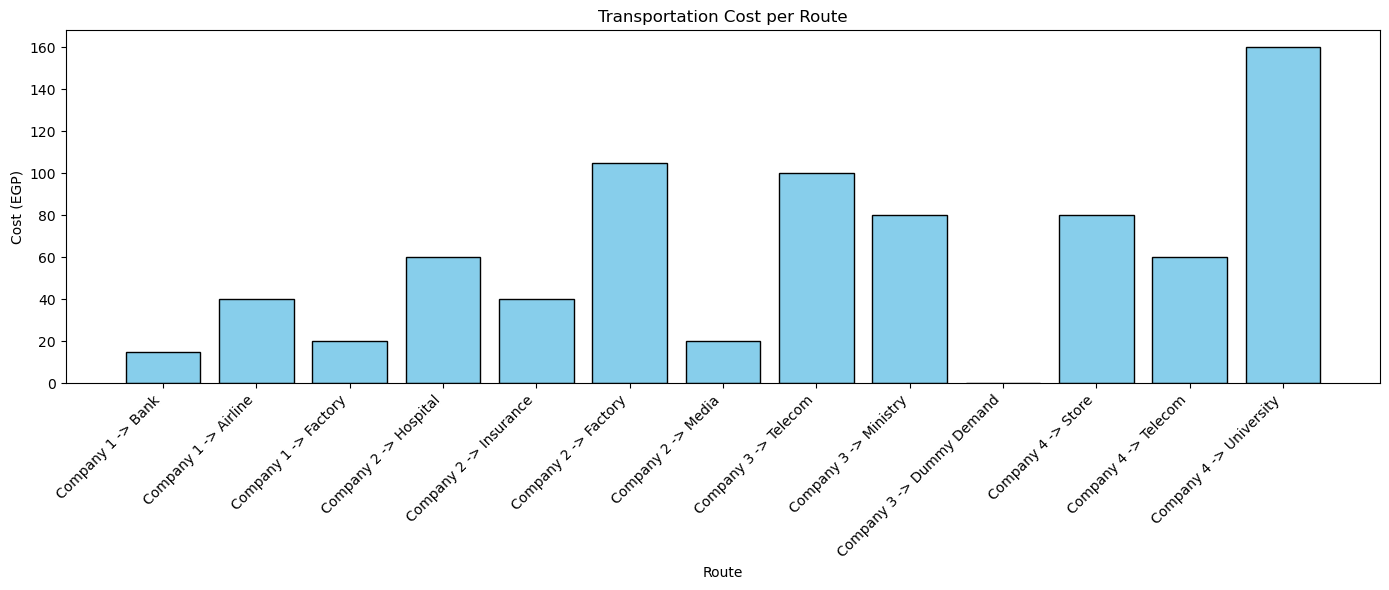

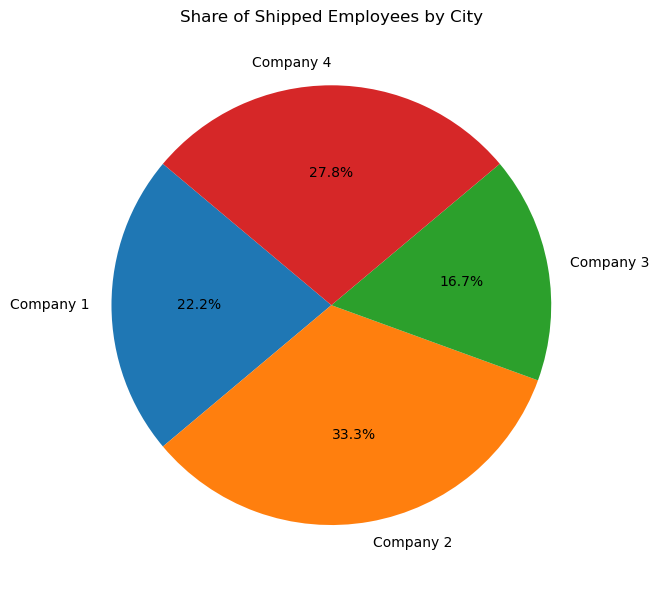


Generating graphs for: SCENARIO 3 - BALANCED SUPPLY AND DEMAND


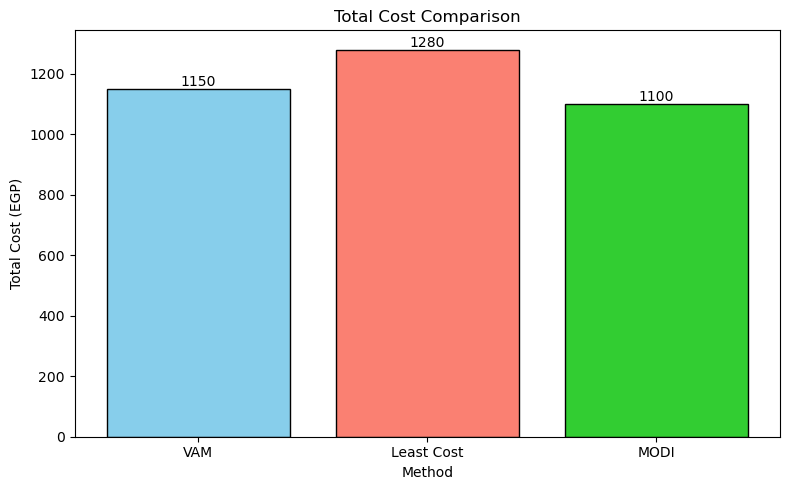

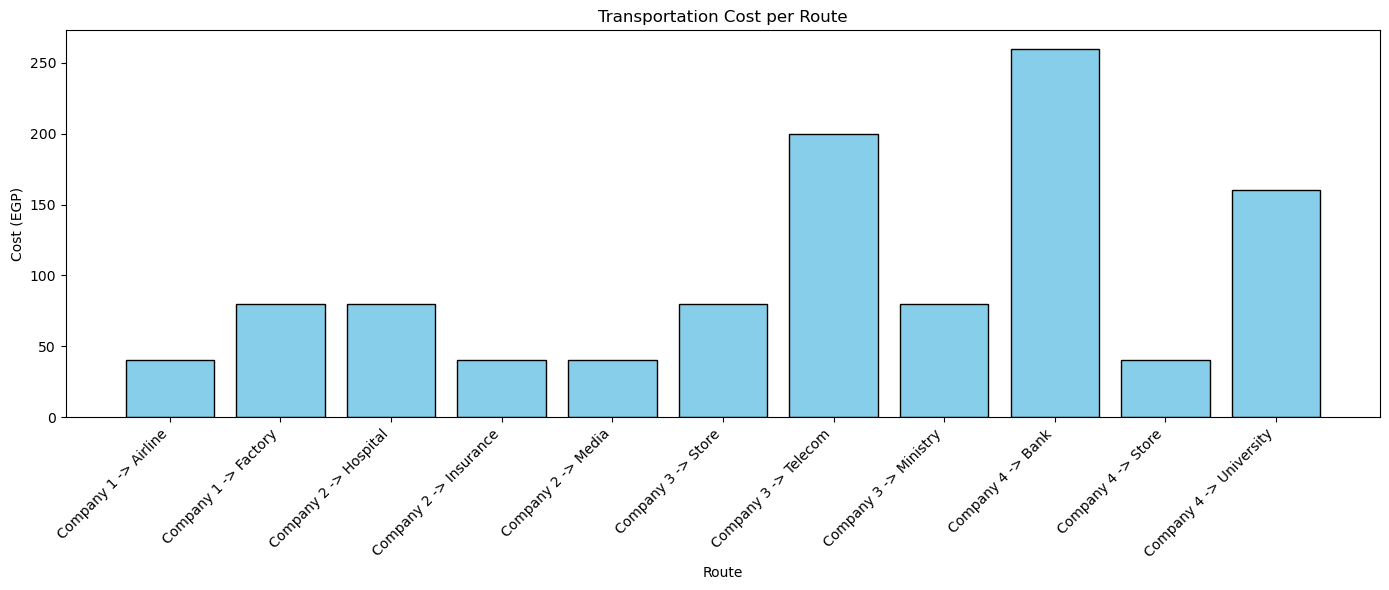

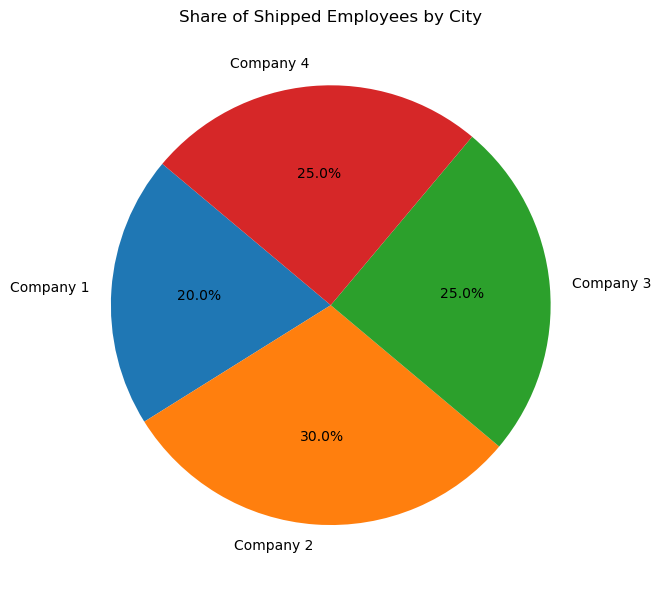



ALL SCENARIOS - MODI COST COMPARISON

SCENARIO 1 - DEMAND GREATER THAN SUPPLY
VAM        = 1310.00 EGP
Least Cost = 1260.00 EGP
MODI       = 1060.00 EGP

SCENARIO 2 - SUPPLY GREATER THAN DEMAND
VAM        = 835.00 EGP
Least Cost = 1235.00 EGP
MODI       = 780.00 EGP

SCENARIO 3 - BALANCED SUPPLY AND DEMAND
VAM        = 1150.00 EGP
Least Cost = 1280.00 EGP
MODI       = 1100.00 EGP


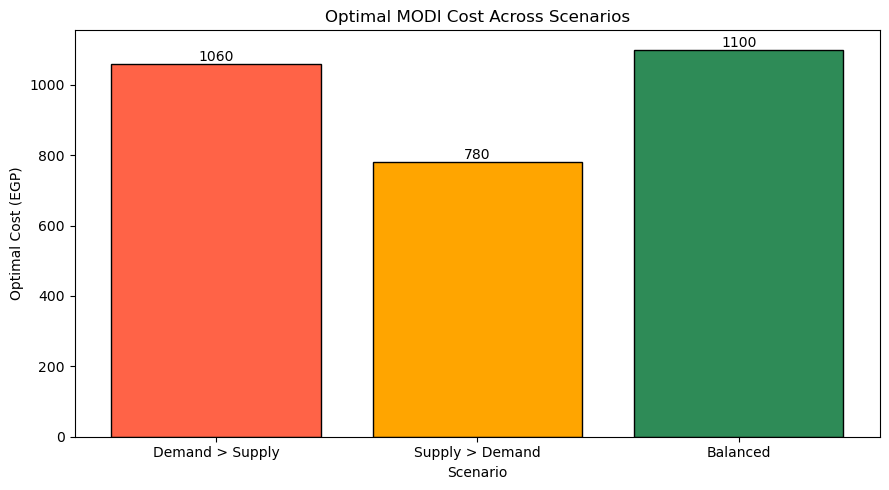

In [2]:
import numpy as np
import matplotlib.pyplot as plt


# =========================================================
# 1. DATA
# =========================================================

# Unit transport cost (EGP per unit)
# Rows = Cities
# Columns = Depots

cost = np.array([
    [1,  3,  9,  8,  5,  2,  2,  4, 12,  3],   # Cairo
    [4,  4, 14, 12,  9,  2,  7,  7, 16,  2],   # Alexandria
    [18, 20, 8, 10, 13, 19, 20, 22, 4, 21],      # Aswan
    [13, 15, 4,  6,  8, 15, 16, 18, 1, 17]       # Luxor
], dtype=np.float64)


cities = [
    "Company 1",
    "Company 2",
    "Company 3",
    "Company 4"
]


depots = [
    "Bank",
    "Hospital",
    "Store",
    "Telecom",
    "University",
    "Insurance",
    "Airline",
    "Factory",
    "Ministry",
    "Media"
]


# Available employees in each city
supply = [40, 60, 50, 50]


# =========================================================
# 2. BALANCE CHECK
# =========================================================

def balance_check(cost, supply, demand, cities, depots):

    cost = cost.copy()
    supply = list(supply)
    demand = list(demand)
    cities = list(cities)
    depots = list(depots)

    total_supply = sum(supply)
    total_demand = sum(demand)

    print("Total Supply  =", total_supply)
    print("Total Demand  =", total_demand)

    # -----------------------------------------------------
    # Balanced
    # -----------------------------------------------------

    if total_supply == total_demand:

        print("\nThe Transportation Problem is BALANCED.")
        print("No dummy row or column is required.")

    # -----------------------------------------------------
    # Demand > Supply
    # -----------------------------------------------------

    elif total_supply < total_demand:

        difference = total_demand - total_supply

        print(
            "\nThe Transportation Problem is NOT BALANCED."
        )

        print(
            "Demand is greater than Supply by",
            difference
        )

        print(
            "Adding a DUMMY SOURCE with supply",
            difference
        )

        # Add dummy source
        cost = np.vstack([
            cost,
            np.zeros(cost.shape[1])
        ])

        supply.append(difference)

        cities.append("Dummy Source")

    # -----------------------------------------------------
    # Supply > Demand
    # -----------------------------------------------------

    else:

        difference = total_supply - total_demand

        print(
            "\nThe Transportation Problem is NOT BALANCED."
        )

        print(
            "Supply is greater than Demand by",
            difference
        )

        print(
            "Adding a DUMMY DEMAND with demand",
            difference
        )

        # Add dummy destination
        cost = np.hstack([
            cost,
            np.zeros((cost.shape[0], 1))
        ])

        demand.append(difference)

        depots.append("Dummy Demand")

    return cost, supply, demand, cities, depots


# =========================================================
# 3. VOGEL'S APPROXIMATION METHOD
# =========================================================

def vogel_approximation(cost, supply, demand):

    cost = cost.copy()

    original_cost = cost.copy()

    supply_left = list(supply)
    demand_left = list(demand)

    allocation = np.zeros_like(cost)

    while (
        np.any(np.array(supply_left) > 0)
        and
        np.any(np.array(demand_left) > 0)
    ):

        row_penalties = []

        # -------------------------------------------------
        # Calculate row penalties
        # -------------------------------------------------

        for i in range(len(supply_left)):

            if supply_left[i] <= 0:
                row_penalties.append(-1)
                continue

            valid_costs = [
                cost[i][j]
                for j in range(len(demand_left))
                if demand_left[j] > 0
                and np.isfinite(cost[i][j])
            ]

            if len(valid_costs) >= 2:

                sorted_costs = sorted(valid_costs)

                penalty = (
                    sorted_costs[1]
                    -
                    sorted_costs[0]
                )

            elif len(valid_costs) == 1:

                penalty = valid_costs[0]

            else:

                penalty = -1

            row_penalties.append(penalty)

        # -------------------------------------------------
        # Calculate column penalties
        # -------------------------------------------------

        col_penalties = []

        for j in range(len(demand_left)):

            if demand_left[j] <= 0:
                col_penalties.append(-1)
                continue

            valid_costs = [
                cost[i][j]
                for i in range(len(supply_left))
                if supply_left[i] > 0
                and np.isfinite(cost[i][j])
            ]

            if len(valid_costs) >= 2:

                sorted_costs = sorted(valid_costs)

                penalty = (
                    sorted_costs[1]
                    -
                    sorted_costs[0]
                )

            elif len(valid_costs) == 1:

                penalty = valid_costs[0]

            else:

                penalty = -1

            col_penalties.append(penalty)

        # -------------------------------------------------
        # Select maximum penalty
        # -------------------------------------------------

        max_row_penalty = max(row_penalties)
        max_col_penalty = max(col_penalties)

        if max_row_penalty >= max_col_penalty:

            i = row_penalties.index(max_row_penalty)

            valid_columns = [
                j
                for j in range(len(demand_left))
                if demand_left[j] > 0
                and np.isfinite(cost[i][j])
            ]

            j = min(
                valid_columns,
                key=lambda x: cost[i][x]
            )

        else:

            j = col_penalties.index(max_col_penalty)

            valid_rows = [
                i
                for i in range(len(supply_left))
                if supply_left[i] > 0
                and np.isfinite(cost[i][j])
            ]

            i = min(
                valid_rows,
                key=lambda x: cost[x][j]
            )

        # -------------------------------------------------
        # Allocate
        # -------------------------------------------------

        quantity = min(
            supply_left[i],
            demand_left[j]
        )

        allocation[i][j] = quantity

        supply_left[i] -= quantity
        demand_left[j] -= quantity

        # Disable completed row
        if supply_left[i] == 0:
            cost[i, :] = np.inf

        # Disable completed column
        if demand_left[j] == 0:
            cost[:, j] = np.inf

    total_cost = np.sum(
        allocation * original_cost
    )

    return allocation, total_cost


# =========================================================
# 4. LEAST COST METHOD
# =========================================================

def least_cost_method(cost, supply, demand):

    cost = cost.copy()

    original_cost = cost.copy()

    supply_left = list(supply)
    demand_left = list(demand)

    allocation = np.zeros_like(cost)

    while (
        np.any(np.array(supply_left) > 0)
        and
        np.any(np.array(demand_left) > 0)
    ):

        # Find the cheapest available cell
        minimum_cost = np.inf
        selected_i = None
        selected_j = None

        for i in range(len(supply_left)):

            for j in range(len(demand_left)):

                if (
                    supply_left[i] > 0
                    and
                    demand_left[j] > 0
                    and
                    cost[i][j] < minimum_cost
                ):

                    minimum_cost = cost[i][j]
                    selected_i = i
                    selected_j = j

        i = selected_i
        j = selected_j

        quantity = min(
            supply_left[i],
            demand_left[j]
        )

        allocation[i][j] = quantity

        supply_left[i] -= quantity
        demand_left[j] -= quantity

        # Disable completed row
        if supply_left[i] == 0:
            cost[i, :] = np.inf

        # Disable completed column
        if demand_left[j] == 0:
            cost[:, j] = np.inf

    total_cost = np.sum(
        allocation * original_cost
    )

    return allocation, total_cost


# =========================================================
# 5. COMPLETE BASIS FOR MODI
# =========================================================

def complete_basis(allocation, cost):

    m, n = cost.shape

    basis = set(
        zip(
            *np.nonzero(allocation)
        )
    )

    basis = {
        (int(i), int(j))
        for i, j in basis
    }

    parent = list(
        range(m + n)
    )

    def find(x):

        while parent[x] != x:

            parent[x] = parent[parent[x]]
            x = parent[x]

        return x

    def union(a, b):

        root_a = find(a)
        root_b = find(b)

        if root_a != root_b:
            parent[root_a] = root_b

    # Existing basic cells
    for i, j in basis:

        union(
            i,
            m + j
        )

    # Add zero cells if needed
    candidates = []

    for i in range(m):

        for j in range(n):

            candidates.append(
                (
                    cost[i][j],
                    i,
                    j
                )
            )

    candidates.sort()

    for _, i, j in candidates:

        if len(basis) >= m + n - 1:
            break

        if find(i) != find(m + j):

            basis.add(
                (i, j)
            )

            union(
                i,
                m + j
            )

    return basis


# =========================================================
# 6. MODI POTENTIALS
# =========================================================

def potentials(cost, basis):

    m, n = cost.shape

    u = [None] * m
    v = [None] * n

    u[0] = 0

    changed = True

    while changed:

        changed = False

        for i, j in basis:

            if (
                u[i] is not None
                and
                v[j] is None
            ):

                v[j] = cost[i][j] - u[i]

                changed = True

            elif (
                v[j] is not None
                and
                u[i] is None
            ):

                u[i] = cost[i][j] - v[j]

                changed = True

    return u, v


# =========================================================
# 7. FIND LOOP PATH
# =========================================================

def loop_path(basis, row, col):

    adjacency = {}

    for i, j in basis:

        adjacency.setdefault(
            ("r", i),
            []
        ).append(
            (
                ("c", j),
                (i, j)
            )
        )

        adjacency.setdefault(
            ("c", j),
            []
        ).append(
            (
                ("r", i),
                (i, j)
            )
        )

    stack = [
        (
            ("r", row),
            []
        )
    ]

    visited = {
        ("r", row)
    }

    while stack:

        node, path = stack.pop()

        if node == ("c", col):

            return path

        for next_node, cell in adjacency.get(
            node,
            []
        ):

            if next_node not in visited:

                visited.add(next_node)

                stack.append(
                    (
                        next_node,
                        path + [cell]
                    )
                )

    return None


# =========================================================
# 8. MODI METHOD
# =========================================================

def modi(cost, start_allocation):

    allocation = start_allocation.copy()

    m, n = cost.shape

    basis = complete_basis(
        allocation,
        cost
    )

    steps = []

    while True:

        u, v = potentials(
            cost,
            basis
        )

        best = None

        # -------------------------------------------------
        # Calculate opportunity costs
        # -------------------------------------------------

        for i in range(m):

            for j in range(n):

                if (i, j) not in basis:

                    delta = (
                        cost[i][j]
                        -
                        u[i]
                        -
                        v[j]
                    )

                    if (
                        delta < -1e-9
                        and
                        (
                            best is None
                            or
                            delta < best[0]
                        )
                    ):

                        best = (
                            delta,
                            i,
                            j
                        )

        # -------------------------------------------------
        # Optimal
        # -------------------------------------------------

        if best is None:

            total_cost = np.sum(
                allocation * cost
            )

            return (
                allocation,
                total_cost,
                steps
            )

        # -------------------------------------------------
        # Entering cell
        # -------------------------------------------------

        delta, i, j = best

        path = loop_path(
            basis,
            i,
            j
        )

        if path is None:

            raise RuntimeError(
                "MODI could not find a closed loop."
            )

        # -------------------------------------------------
        # + and - positions
        # -------------------------------------------------

        minus_cells = path[0::2]
        plus_cells = path[1::2]

        theta = min(
            allocation[a][b]
            for a, b in minus_cells
        )

        # -------------------------------------------------
        # Leaving cell
        # -------------------------------------------------

        leaving_cell = next(
            cell
            for cell in minus_cells
            if allocation[
                cell[0]
            ][
                cell[1]
            ] == theta
        )

        before_cost = np.sum(
            allocation * cost
        )

        # Entering cell gets +
        allocation[i][j] += theta

        # Plus cells
        for a, b in plus_cells:

            allocation[a][b] += theta

        # Minus cells
        for a, b in minus_cells:

            allocation[a][b] -= theta

        basis.remove(
            leaving_cell
        )

        basis.add(
            (i, j)
        )

        after_cost = np.sum(
            allocation * cost
        )

        steps.append(
            {
                "entering": (i, j),
                "delta": delta,
                "theta": theta,
                "before": before_cost,
                "after": after_cost
            }
        )


# =========================================================
# 9. PRINT ALLOCATION
# =========================================================

def print_allocation(
    allocation,
    rows,
    cols
):

    for i in range(len(rows)):

        for j in range(len(cols)):

            if allocation[i][j] > 0:

                print(
                    f"{rows[i]} -> "
                    f"{cols[j]} = "
                    f"{int(allocation[i][j])} units"
                )


# =========================================================
# 10. SOLVE ONE SCENARIO
# =========================================================

def solve_case(
    title,
    cost,
    supply,
    demand,
    cities,
    depots
):

    print("\n")
    print("=" * 70)
    print(title)
    print("=" * 70)

    # -----------------------------------------------------
    # Balance Check
    # -----------------------------------------------------

    print("\n===== Balance Check =====")

    c, s, d, rows, cols = balance_check(
        cost,
        supply,
        demand,
        cities,
        depots
    )

    # -----------------------------------------------------
    # VAM
    # -----------------------------------------------------

    vam_allocation, vam_cost = (
        vogel_approximation(
            c,
            s,
            d
        )
    )

    print(
        "\n===== Vogel's Approximation Method (VAM) ====="
    )

    print_allocation(
        vam_allocation,
        rows,
        cols
    )

    print(
        "Total cost by VAM =",
        vam_cost,
        "EGP"
    )

    # -----------------------------------------------------
    # Least Cost
    # -----------------------------------------------------

    least_allocation, least_cost = (
        least_cost_method(
            c,
            s,
            d
        )
    )

    print(
        "\n===== Least Cost Method ====="
    )

    print_allocation(
        least_allocation,
        rows,
        cols
    )

    print(
        "Total cost by Least Cost =",
        least_cost,
        "EGP"
    )

    # -----------------------------------------------------
    # Compare initial solutions
    # -----------------------------------------------------

    print(
        "\n===== Initial Solution Comparison ====="
    )

    print(
        f"VAM        = {vam_cost:.2f} EGP"
    )

    print(
        f"Least Cost = {least_cost:.2f} EGP"
    )

    if vam_cost < least_cost:

        print(
            "VAM gives the better initial solution."
        )

    elif least_cost < vam_cost:

        print(
            "Least Cost gives the better initial solution."
        )

    else:

        print(
            "Both methods give the same initial cost."
        )

    # -----------------------------------------------------
    # MODI
    # -----------------------------------------------------

    modi_allocation, modi_cost, steps = modi(
        c,
        vam_allocation
    )

    print(
        "\n===== MODI - Optimal Solution ====="
    )

    print_allocation(
        modi_allocation,
        rows,
        cols
    )

    print(
        "Total cost by MODI =",
        modi_cost,
        "EGP"
    )

    print(
        "Number of MODI improvement steps =",
        len(steps)
    )

    # -----------------------------------------------------
    # Final comparison
    # -----------------------------------------------------

    print(
        "\n===== Final Comparison ====="
    )

    print(
        f"VAM        : {vam_cost:.2f} EGP"
    )

    print(
        f"Least Cost : {least_cost:.2f} EGP"
    )

    print(
        f"MODI       : {modi_cost:.2f} EGP"
    )

    return {
        "title": title,
        "rows": rows,
        "cols": cols,
        "cost": c,
        "supply": s,
        "demand": d,
        "vam": vam_cost,
        "least": least_cost,
        "modi": modi_cost,
        "alloc": modi_allocation
    }


# =========================================================
# 11. PLOT ONE SCENARIO
# =========================================================

def plot_case(result):

    rows = result["rows"]
    cols = result["cols"]

    cost_matrix = result["cost"]
    allocation = result["alloc"]

    # -----------------------------------------------------
    # Graph 1: Method Cost Comparison
    # -----------------------------------------------------

    methods = [
        "VAM",
        "Least Cost",
        "MODI"
    ]

    costs = [
        result["vam"],
        result["least"],
        result["modi"]
    ]

    plt.figure(
        figsize=(8, 5)
    )

    plt.bar(
        methods,
        costs,
        color=[
            "skyblue",
            "salmon",
            "limegreen"
        ],
        edgecolor="black"
    )

    plt.title(
        "Total Cost Comparison"
    )

    plt.xlabel(
        "Method"
    )

    plt.ylabel(
        "Total Cost (EGP)"
    )

    for i, value in enumerate(costs):

        plt.text(
            i,
            value,
            f"{value:.0f}",
            ha="center",
            va="bottom"
        )

    plt.tight_layout()

    plt.show()

    # -----------------------------------------------------
    # Graph 2: Cost per Route
    # -----------------------------------------------------

    routes = []
    route_costs = []

    for i in range(len(rows)):

        for j in range(len(cols)):

            if allocation[i][j] > 0:

                routes.append(
                    f"{rows[i]} -> {cols[j]}"
                )

                route_costs.append(
                    allocation[i][j]
                    *
                    cost_matrix[i][j]
                )

    plt.figure(
        figsize=(14, 6)
    )

    plt.bar(
        routes,
        route_costs,
        color="skyblue",
        edgecolor="black"
    )

    plt.title(
        "Transportation Cost per Route"
    )

    plt.xlabel(
        "Route"
    )

    plt.ylabel(
        "Cost (EGP)"
    )

    plt.xticks(
        rotation=45,
        ha="right"
    )

    plt.tight_layout()

    plt.show()

    # -----------------------------------------------------
    # Graph 3: Employees Shipped by City
    # -----------------------------------------------------

    real_rows = [
        i
        for i, name in enumerate(rows)
        if not name.startswith("Dummy")
    ]

    real_cols = [
        j
        for j, name in enumerate(cols)
        if not name.startswith("Dummy")
    ]

    city_names = [
        rows[i]
        for i in real_rows
    ]

    shipped_units = [
        allocation[
            i,
            real_cols
        ].sum()
        for i in real_rows
    ]

    plt.figure(
        figsize=(8, 6)
    )

    plt.pie(
        shipped_units,
        labels=city_names,
        autopct="%1.1f%%",
        startangle=140
    )

    plt.title(
        "Share of Shipped Employees by City"
    )

    plt.tight_layout()

    plt.show()


# =========================================================
# 12. THREE SCENARIOS
# =========================================================

def run_three_scenarios():

    print("\n")
    print("=" * 70)
    print(
        "TRANSPORTATION PROBLEM - THREE SCENARIOS"
    )
    print("=" * 70)

    total_supply = sum(supply)

    print(
        "\nTotal Supply =",
        total_supply
    )

    # =====================================================
    # SCENARIO 1
    # Demand > Supply
    # =====================================================

    demand_more = [
        30,
        30,
        20,
        20,
        20,
        20,
        20,
        20,
        20,
        20
    ]

    # Total = 220
    # Supply = 200
    # Difference = 20


    # =====================================================
    # SCENARIO 2
    # Supply > Demand
    # =====================================================

    demand_less = [
        15,
        15,
        20,
        20,
        20,
        20,
        20,
        20,
        20,
        10
    ]

    # Total = 180
    # Supply = 200
    # Difference = 20


    # =====================================================
    # SCENARIO 3
    # Balanced
    # =====================================================

    demand_equal = [
        20,
        20,
        20,
        20,
        20,
        20,
        20,
        20,
        20,
        20
    ]

    # Total = 200
    # Supply = 200


    scenarios = [

        (
            "SCENARIO 1 - DEMAND GREATER THAN SUPPLY",
            demand_more
        ),

        (
            "SCENARIO 2 - SUPPLY GREATER THAN DEMAND",
            demand_less
        ),

        (
            "SCENARIO 3 - BALANCED SUPPLY AND DEMAND",
            demand_equal
        )

    ]


    results = []


    # =====================================================
    # Solve all scenarios
    # =====================================================

    for title, current_demand in scenarios:

        result = solve_case(
            title,
            cost,
            supply,
            current_demand,
            cities,
            depots
        )

        results.append(result)


    # =====================================================
    # Plot each scenario
    # =====================================================

    for result in results:

        print(
            "\nGenerating graphs for:",
            result["title"]
        )

        plot_case(result)


    # =====================================================
    # Compare all scenarios
    # =====================================================

    print("\n")
    print("=" * 70)
    print(
        "ALL SCENARIOS - MODI COST COMPARISON"
    )
    print("=" * 70)

    for result in results:

        print(
            "\n" + result["title"]
        )

        print(
            f"VAM        = {result['vam']:.2f} EGP"
        )

        print(
            f"Least Cost = {result['least']:.2f} EGP"
        )

        print(
            f"MODI       = {result['modi']:.2f} EGP"
        )


    # =====================================================
    # Final Scenario Graph
    # =====================================================

    scenario_names = [
        "Demand > Supply",
        "Supply > Demand",
        "Balanced"
    ]

    modi_costs = [
        result["modi"]
        for result in results
    ]

    plt.figure(
        figsize=(9, 5)
    )

    plt.bar(
        scenario_names,
        modi_costs,
        color=[
            "tomato",
            "orange",
            "seagreen"
        ],
        edgecolor="black"
    )

    plt.title(
        "Optimal MODI Cost Across Scenarios"
    )

    plt.xlabel(
        "Scenario"
    )

    plt.ylabel(
        "Optimal Cost (EGP)"
    )

    for i, value in enumerate(modi_costs):

        plt.text(
            i,
            value,
            f"{value:.0f}",
            ha="center",
            va="bottom"
        )

    plt.tight_layout()

    plt.show()


# =========================================================
# 13. RUN PROGRAM
# =========================================================

run_three_scenarios()